# Phase 10 Part 1C — CLEAN-v3 DeepLabV3+ Training Review

**Model:** Gemini 3.1 Pro High
**Date:** 2026-09-20
**Experiment:** `phase10_kub_deeplabv3plus_seed42_512_clean_v3`
**Architecture:** DeepLabV3+ — `deeplabv3plus_resnet50_os16` (ResNet-50, **no pretrained weights**, output stride 16)
**Manifest:** `phase4_v3` | **Taxonomy:** `kub_size_clean_v3_v1`

---

> **READ-ONLY REVIEWER NOTEBOOK** — does NOT train. Reviews a completed run.
> TEST locked (reads = 0). **No winner is declared**; the final Phase-10 comparison
> is NOT started and no ranking or significance test appears here.
>
> **Paired gallery:** uses the SAME frozen 16-case KUB VAL selection as UNet,
> Attention U-Net, and UNet++ (canonical SHA `10ad09cb…`).
>
> **Per-epoch table:** this notebook displays the COMPLETE epoch-by-epoch results
> (one row per completed epoch, untruncated) per the new canonical rule.


## 2. Scope and Governance

| Item | Value |
|------|-------|
| Manifest | `phase4_v3` |
| Taxonomy | `kub_size_clean_v3_v1` |
| Target | `mask > 0` via `binarize_mask` |
| Resolution | 512, 1 channel |
| VAL scope | KUB-only 280 (hard-gated) |
| TEST | LOCKED (reads = 0) |
| Cross-model comparison | **NOT PERFORMED** |
| Winner | **NOT DECLARED** |

Phase 10 status: UNet (09), Attention U-Net (1A), UNet++ (1B), DeepLabV3+ (1C) are now all
complete as **individual** clean-v3 runs. The final Phase-10 comparison is still
**NOT STARTED** and requires separate authorization.


In [1]:
%matplotlib inline
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# FULL table display (no truncation) - canonical per-epoch rule
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks' / 'phasewise' / 'phase_10_baseline_comparison' / 'code'))
import phase10_deeplabv3plus_review as rv

print('Experiment  :', rv.EXPERIMENT_ID)
print('Architecture: deeplabv3plus_resnet50_os16')
print('Historical  :', rv.HISTORICAL_EXPERIMENT_ID)


Experiment  : phase10_kub_deeplabv3plus_seed42_512_clean_v3
Architecture: deeplabv3plus_resnet50_os16
Historical  : phase10_kub_deeplabv3plus_seed42_512


## 3–4. Historical DeepLabV3+ Provenance and Architecture Reconstruction


In [2]:
sa = rv.load_start_audit()
print('=== HISTORICAL PROVENANCE (from start audit) ===')
for k in ['historical_experiment_id','historical_architecture','historical_best_epoch',
          'historical_best_val_macro_dice','historical_final_epoch','historical_trainer',
          'historical_best_checkpoint_sha','historical_latest_checkpoint_sha',
          'historical_history_sha','historical_model_source_sha']:
    print(f'  {k}: {sa.get(k)}')
print()
print('=== ARCHITECTURE PROOF ===')
print(json.dumps(sa.get('architecture_proof', {}), indent=2))
print()
print('backbone            :', sa.get('backbone'), '| pretrained:', sa.get('backbone_pretrained'))
print('output_stride       :', sa.get('output_stride'))
print('aspp_rates          :', sa.get('aspp_rates'))
print('auxiliary_head      :', sa.get('auxiliary_head'))
print('parameter_count     :', f"{sa.get('parameter_count'):,}")


=== HISTORICAL PROVENANCE (from start audit) ===
  historical_experiment_id: phase10_kub_deeplabv3plus_seed42_512
  historical_architecture: deeplabv3plus_resnet50_os16
  historical_best_epoch: 37
  historical_best_val_macro_dice: 0.7487905025482178
  historical_final_epoch: 52
  historical_trainer: scripts/training/train_phase10_baselines.py
  historical_best_checkpoint_sha: d07618ed2dd838ba0f3dc292c9e7bfd6309436677aa849129d33875e026f2cfd
  historical_latest_checkpoint_sha: ea91b3f05d1cac6834540b2ae9b4210377136d73c773e5a6304ac6761e950898
  historical_history_sha: 1a2fa2bf9c946202d900ec575c111155032f25e84de6a89e62044de5edb103e3
  historical_model_source_sha: 751a1ead9aca93c7372750924f7483b3de3ad3f5f40edd3a648e9e39bdd77406

=== ARCHITECTURE PROOF ===
{
  "method": "instantiated DeepLabV3Plus(in=1,out=1,base=32) and loaded historical state_dict",
  "missing_keys": [],
  "unexpected_keys": [],
  "instantiated_param_count": 40340769,
  "matches_summary_json": true
}

backbone            : 

## 5. Clean-v3 Experiment Identity


In [3]:
print('=== CLEAN-v3 IDENTITY ===')
print(f'Experiment ID : {rv.EXPERIMENT_ID}')
print(f'Architecture  : deeplabv3plus_resnet50_os16')
print(f'Config SHA    : {rv.EXPECTED_CONFIG_SHA}')
ca = rv.load_completion_audit()
print(f'History SHA   : {ca.get("history_sha")}')
print(f'Best pt SHA   : {ca.get("best_checkpoint_sha")}')
print(f'Latest pt SHA : {ca.get("latest_checkpoint_sha")}')
print(f'Manifest      : phase4_v3')
print(f'Taxonomy      : kub_size_clean_v3_v1')


=== CLEAN-v3 IDENTITY ===
Experiment ID : phase10_kub_deeplabv3plus_seed42_512_clean_v3
Architecture  : deeplabv3plus_resnet50_os16
Config SHA    : a5220e3135618513a71e0094197b2cffe0aef9334f7d53e39642c7a00ddd5b57
History SHA   : 9c3a4611f0f38b474aa18537b0509bf9a4cb539baf077e6ba12c7880a73cd01f
Best pt SHA   : f519027ba1a3a4d6212d83fecd4379f61f71bc05b0751924b9660da08d597dad
Latest pt SHA : 69267fd0cd2104cb474665bda68f3f9a1b4c2c4dc9e074b603fea921434022ed
Manifest      : phase4_v3
Taxonomy      : kub_size_clean_v3_v1


## 6. v2 → v3 Protocol Diff


In [4]:
d = rv.load_protocol_diff()
print('=== PROTOCOL DIFF ===')
print('Fields compared:', len(d), '| CHANGED:', int((d.same_or_changed=='CHANGED').sum()),
      '| SAME:', int((d.same_or_changed=='SAME').sum()))
print()
print(d[d.same_or_changed=='CHANGED'][['field','historical_v2','clean_v3','change_reason']].to_string(index=False))
un = d[(d.same_or_changed=='CHANGED') & (d.scientifically_material==True)]
print()
print('Unauthorized material differences:', len(un))
assert len(un) == 0
print('All changes governance/provenance only - PASS')


=== PROTOCOL DIFF ===
Fields compared: 58 | CHANGED: 8 | SAME: 50

             field                        historical_v2                                      clean_v3                                        change_reason
     experiment_id phase10_kub_deeplabv3plus_seed42_512 phase10_kub_deeplabv3plus_seed42_512_clean_v3                              Clean-v3 logical run ID
  manifest_version                            phase4_v2                                     phase4_v3              Clean manifest with leakage remediation
       taxonomy_id                                  NaN                          kub_size_clean_v3_v1                              Frozen taxonomy binding
           monitor        val_macro_dice_true_per_image                                val_macro_dice Canonical monitor string (identical macro semantics)
   device_contract                             implicit                 get_device(require_cuda=True)                              Fail-loud CUDA contract
   

## 7. Frozen Protocol (from physical config)


In [5]:
cfg = rv.load_config()
m,t,o,s,a = cfg['model'],cfg['training'],cfg['optimizer'],cfg['scheduler'],cfg['augmentation']
print('=== FROZEN PROTOCOL ===')
print(f"Architecture : {m['name']} | backbone {m['backbone']} | pretrained={m['backbone_pretrained']}")
print(f"OS / ASPP    : os={m['output_stride']} rates={m['aspp']['rates']} out={m['aspp']['out_channels']} dropout={m['aspp']['project_dropout']}")
print(f"Low-level proj: {m['low_level_projection_channels']} ch | decoder {m['decoder_channels']} | aux={m['auxiliary_head']}")
print(f"Input handling: {m['input_channel_handling']}")
print(f"Resolution   : {cfg['input_resolution']}")
print(f"Preprocessing: {cfg['preprocessing']['strategy']} ({cfg['preprocessing']['mask_interpolation']} mask)")
print(f"Loss         : {cfg['loss']['name']} {cfg['loss']['bce_weight']}/{cfg['loss']['dice_weight']} eps={cfg['loss']['dice_epsilon']}")
print(f"Optimizer    : {o['name']} lr={o['learning_rate']} wd={o['weight_decay']}")
print(f"Scheduler    : {s['name']} T_max={s['max_epochs']}")
print(f"Batch        : {t['batch_size']} (accum {t['gradient_accumulation_steps']}, eff {t['effective_batch_size']})")
print(f"AMP/seed     : {t['amp']} / {t['seed']}")
print(f"Max epochs   : {t['max_epochs']} patience {t['early_stopping_patience']}")
print(f"Monitor/thr  : {t['monitor']} / {t['threshold']}")
print(f"Grad clipping: {t.get('gradient_clipping')}")
print(f"Augmentation : hflip={a['horizontal_flip_probability']} rot=+/-{a['rotation_degrees']} bright=+/-{a['brightness']} contrast=+/-{a['contrast']} vflip={a['vertical_flip']}")
print(f"Init         : {cfg['initialization']['policy']}")
print(f"allow_test   : {cfg['allow_test']}")


=== FROZEN PROTOCOL ===
Architecture : deeplabv3plus | backbone resnet50 | pretrained=False
OS / ASPP    : os=16 rates=[6, 12, 18] out=256 dropout=0.1
Low-level proj: 48 ch | decoder [304, 256, 256] | aux=False
Input handling: backbone.conv1 replaced with Conv2d(1, 64, 7, stride=2, padding=3, bias=False)
Resolution   : 512
Preprocessing: aspect_ratio_resize_symmetric_pad (nearest mask)
Loss         : bce_dice 0.5/0.5 eps=1e-06
Optimizer    : AdamW lr=0.0001 wd=0.0001
Scheduler    : CosineAnnealingLR T_max=100
Batch        : 4 (accum 1, eff 4)
AMP/seed     : True / 42
Max epochs   : 100 patience 15
Monitor/thr  : val_macro_dice / 0.5
Grad clipping: None
Augmentation : hflip=0.5 rot=+/-5.0 bright=+/-0.1 contrast=+/-0.1 vflip=False
Init         : random_kaiming_no_pretrained_weights
allow_test   : False


## 8. Artifact Provenance


In [6]:
art = rv.verify_artifact_shas()
print('=== ARTIFACT SHA VERIFICATION ===')
for k,v in art.items(): print(f'  {k}: {v}')
assert art['all_pass']
print('\nALL ARTIFACT SHAS VERIFIED - PASS')


=== ARTIFACT SHA VERIFICATION ===
  config_match: True
  config_sha: a5220e3135618513a71e0094197b2cffe0aef9334f7d53e39642c7a00ddd5b57
  best_pt_match: True
  best_pt_sha: f519027ba1a3a4d6212d83fecd4379f61f71bc05b0751924b9660da08d597dad
  latest_pt_match: True
  latest_pt_sha: 69267fd0cd2104cb474665bda68f3f9a1b4c2c4dc9e074b603fea921434022ed
  history_match: True
  history_sha: 9c3a4611f0f38b474aa18537b0509bf9a4cb539baf077e6ba12c7880a73cd01f
  taxonomy_match: True
  taxonomy_sha: 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
  runner_sha: d1c5174c3bc6db09f03756ee93f2cf1d122f7a52731d88577da5f8c6a5ef3f33
  protocol_diff_sha: 80b3cb6fe4809abb0baada882c4cc1c305b16c0f10b1c7a0c0f98b84e7ce1fef
  all_pass: True

ALL ARTIFACT SHAS VERIFIED - PASS


## 9. History Integrity


In [7]:
df = rv.load_history()
hi = rv.check_history_integrity(df)
print('=== HISTORY INTEGRITY ===')
for k,v in hi.items(): print(f'  {k}: {v}')
assert hi['contiguous_epochs'] and hi['no_duplicates']
assert hi['unique_strict_max'] and hi['stop_consistent']
assert hi['no_nan'] and hi['finite_losses']
print('\nHISTORY INTEGRITY - PASS')


=== HISTORY INTEGRITY ===
  row_count: 67
  contiguous_epochs: True
  no_duplicates: True
  best_epoch: 52
  best_val_dice: 0.7509140344161673
  best_val_iou: 0.6460492792430865
  best_val_precision: 0.7943328495850855
  best_val_recall: 0.7822983241135557
  unique_strict_max: True
  final_epoch: 67
  final_bad_epochs: 15
  stop_consistent: True
  improved_count: 23
  no_nan: True
  finite_losses: True

HISTORY INTEGRITY - PASS


## 10. Complete Epoch-by-Epoch Training Results

**CANONICAL RULE:** exactly one row per completed epoch, displayed **in full** (no
`head()`/`tail()`, no truncation). Source of truth = immutable `history.csv`.
Derived columns (`delta_*`, `is_*`, `epochs_since_best`) are reviewer-only and are
**never** written back to `history.csv`.


In [8]:
tbl = rv.build_epoch_table(df)
v = rv.verify_epoch_table(tbl, df)
print('=== EPOCH TABLE INTEGRITY SUMMARY ===')
for k,val in v.items(): print(f'  {k}: {val}')
print()
assert v['integrity_pass'], 'Epoch table integrity FAILED'
assert v['row_count_matches_history'], 'Row count != history rows'
print('INTEGRITY: PASS')
print()
print(f"Rendering ALL {len(tbl)} epoch rows (complete, untruncated):")
display(tbl)


=== EPOCH TABLE INTEGRITY SUMMARY ===
  epochs_expected: 67
  rows: 67
  row_count_matches_history: True
  unique_epochs: 67
  first_epoch: 1
  last_epoch: 67
  missing_epochs: []
  duplicate_epochs: []
  contiguous_1_to_N: True
  best_epoch: 52
  improvement_events: 23
  longest_no_improvement_streak: 15
  final_bad_epochs: 15
  integrity_pass: True

INTEGRITY: PASS

Rendering ALL 67 epoch rows (complete, untruncated):


,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,1,0.377359,0.349518,0.487975,0.407391,0.870639,0.504660,0.000100,0.487975,1,0,188.1,BEST_SAVED,NaN,NaN,True,False,0
1,2,0.330579,0.314964,0.540444,0.460717,0.769889,0.578849,0.000100,0.540444,1,0,74.1,BEST_SAVED,0.052469,0.052469,True,False,0
2,3,0.307240,0.299174,0.563059,0.480463,0.749197,0.596709,0.000100,0.563059,1,0,73.8,BEST_SAVED,0.022615,0.022615,True,False,0
3,4,0.287705,0.291801,0.574313,0.487857,0.736589,0.615886,0.000100,0.574313,1,0,74.1,BEST_SAVED,0.011254,0.011254,True,False,0
4,5,0.273234,0.300474,0.571880,0.480890,0.696173,0.606999,0.000099,0.574313,0,1,73.4,LATEST_ONLY,-0.002432,0.000000,False,False,1
5,6,0.261933,0.269859,0.602290,0.513627,0.702040,0.631256,0.000099,0.602290,1,0,73.4,BEST_SAVED,0.030410,0.027978,True,False,0
6,7,0.246003,0.270271,0.610485,0.516051,0.617278,0.741697,0.000099,0.610485,1,0,73.3,BEST_SAVED,0.008194,0.008194,True,False,0
7,8,0.233239,0.248815,0.645464,0.541690,0.721210,0.702844,0.000098,0.645464,1,0,74.8,BEST_SAVED,0.034979,0.034979,True,False,0
8,9,0.221540,0.234570,0.669442,0.563907,0.757588,0.721188,0.000098,0.669442,1,0,73.4,BEST_SAVED,0.023978,0.023978,True,False,0
9,10,0.213646,0.225732,0.683498,0.576951,0.709659,0.729663,0.000098,0.683498,1,0,73.2,BEST_SAVED,0.014057,0.014057,True,False,0


In [9]:
# Save machine-readable epoch table
p = rv.save_epoch_table(tbl)
print(f'Epoch table saved: {p}')
print('Epoch table SHA-256:', rv.sha256_file(p))
print(f"Rows: {len(tbl)} | History rows: {len(df)} | Match: {len(tbl)==len(df)}")


Epoch table saved: D:\Softfors\jup\reports\tables\phase10_deeplabv3plus_clean_v3_epoch_results.csv
Epoch table SHA-256: 8320b24653129f2bbde10cd7084bb6ef7741fb7756cdc22c7a3c3873684252fe
Rows: 67 | History rows: 67 | Match: True


## 11. Training Curves


Curves saved: D:\Softfors\jup\reports\figures\phase10_deeplabv3plus_clean_v3_training_curves_review.png


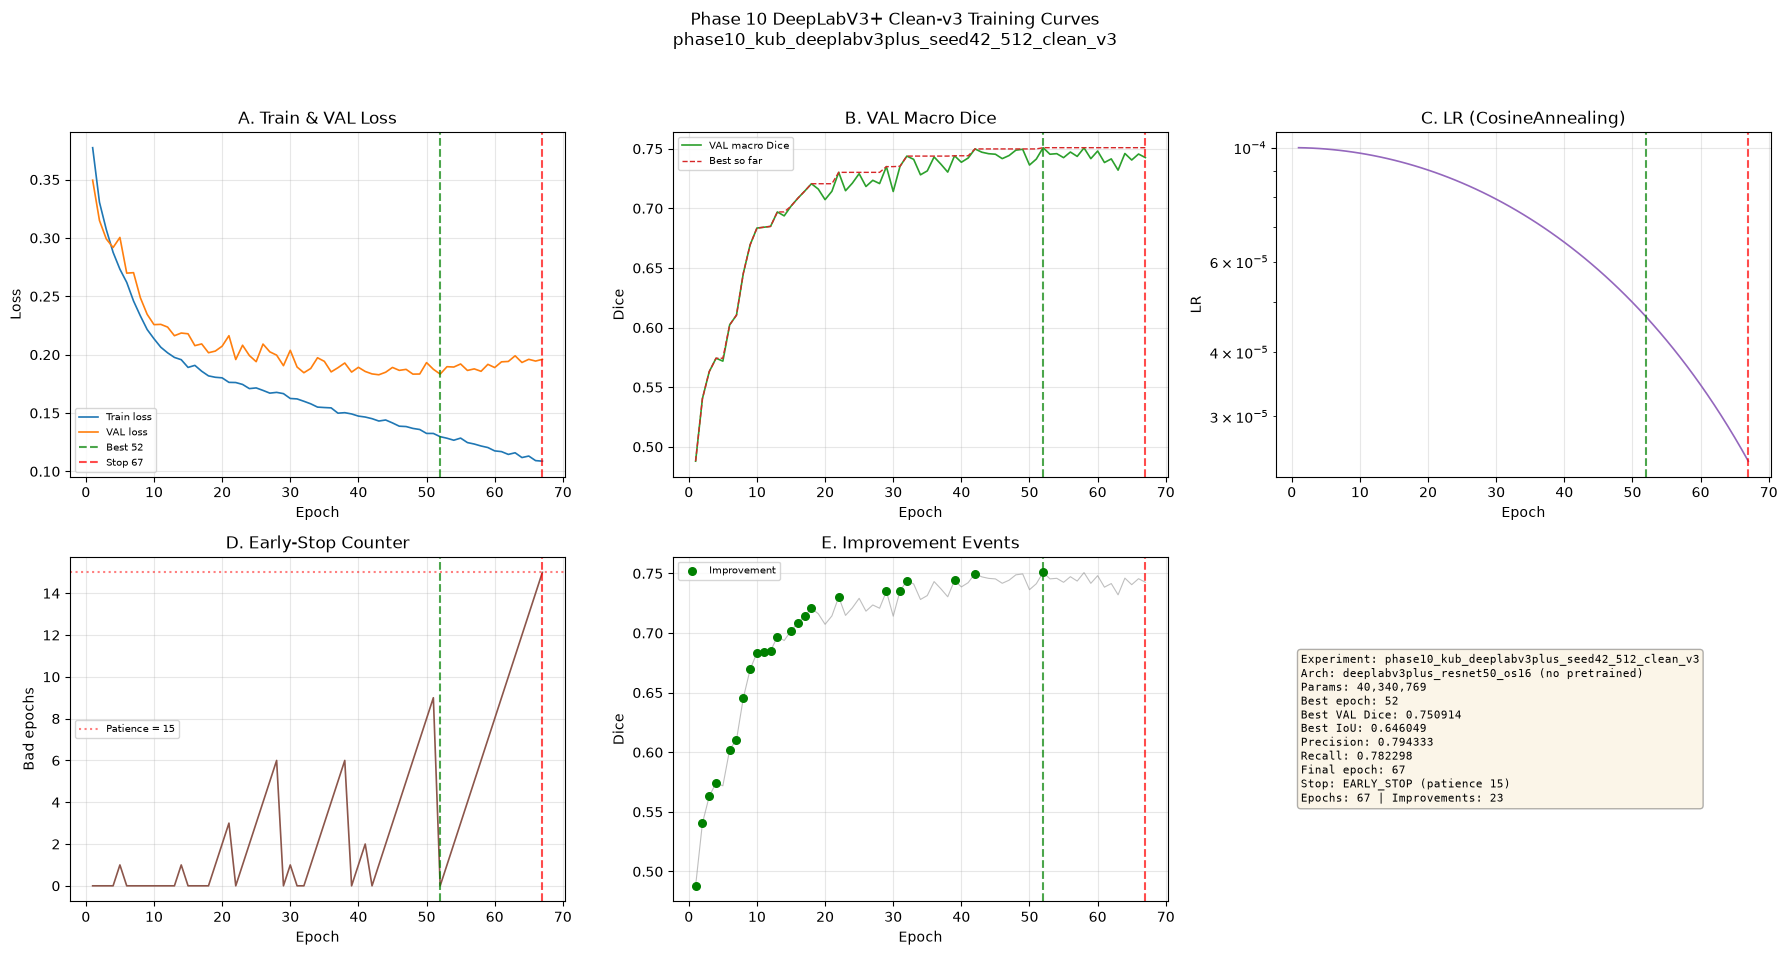

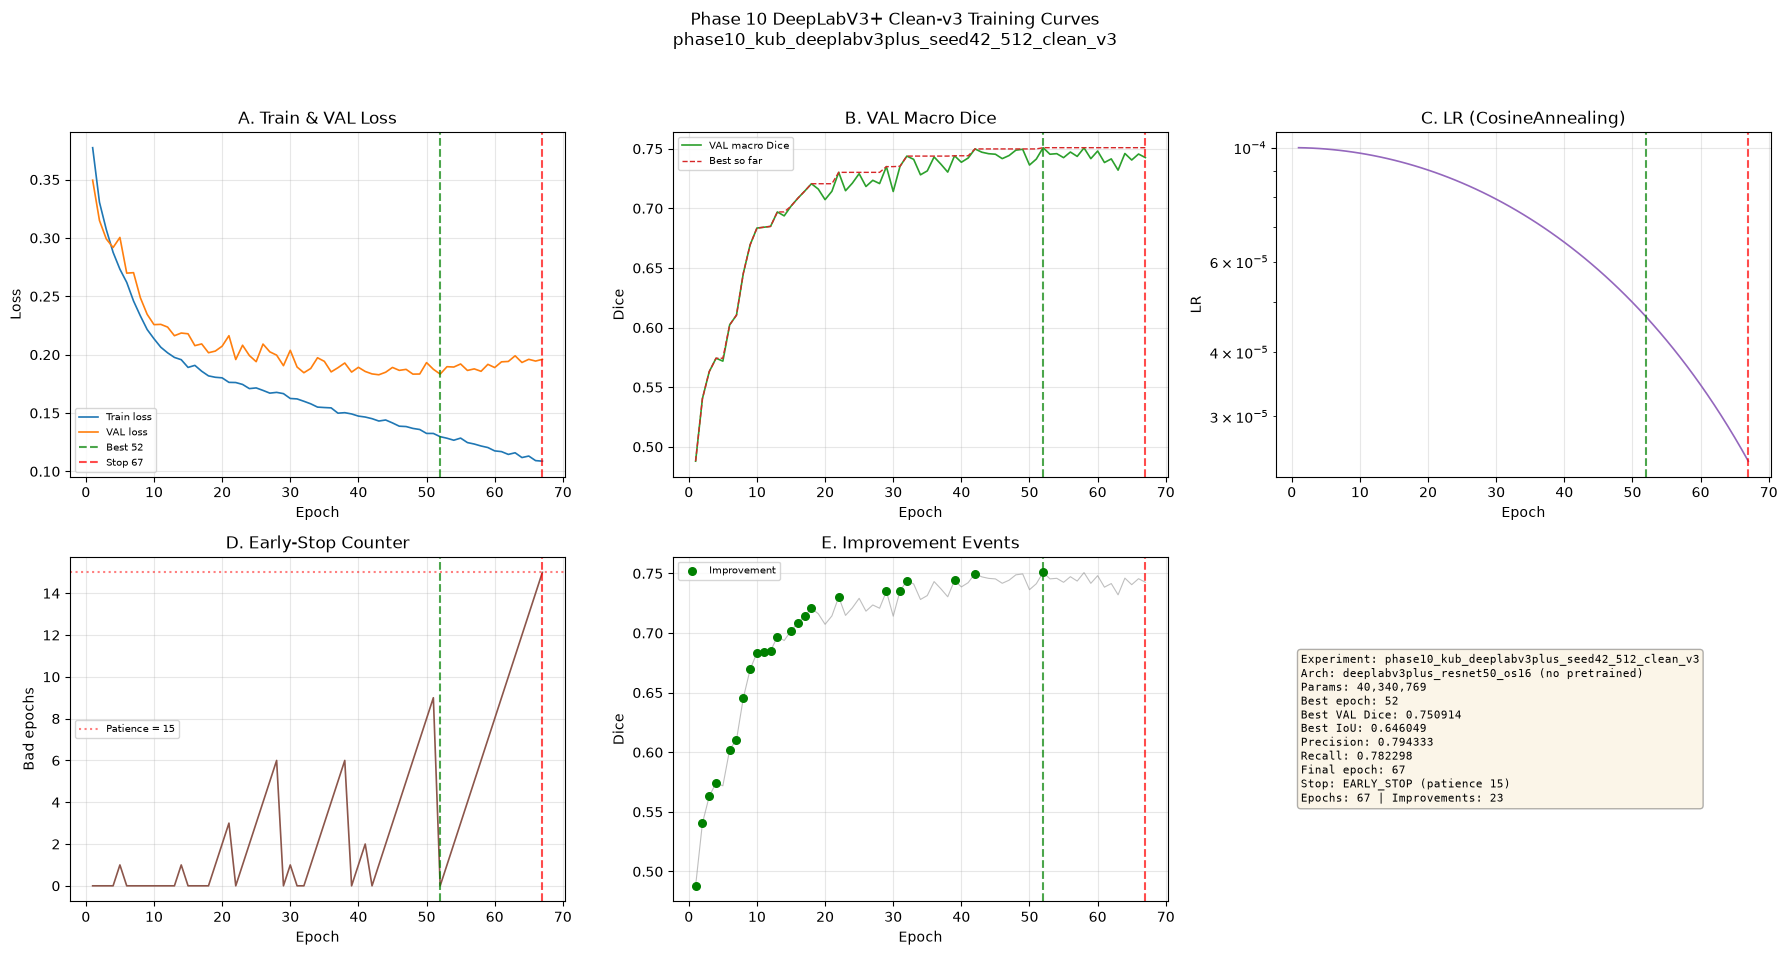

In [10]:
fig = rv.plot_training_curves(df)
cp = PROJECT_ROOT / 'reports' / 'figures' / 'phase10_deeplabv3plus_clean_v3_training_curves_review.png'
fig.savefig(cp, dpi=150, bbox_inches='tight')
print(f'Curves saved: {cp}')
display(fig)


## 12. Best-Checkpoint Verification


In [11]:
b = rv.check_best_checkpoint_consistency()
print('=== BEST CHECKPOINT ===')
for k,val in b.items(): print(f'  {k}: {val}')
assert b['all_pass']
print('\nBEST CHECKPOINT - PASS')


=== BEST CHECKPOINT ===
  epoch_matches: True
  experiment_id_matches: True
  manifest_matches: True
  taxonomy_matches: True
  seed_matches: True
  model_matches: True
  resolution_matches: True
  threshold_matches: True
  score_agrees_with_history: True
  all_pass: True
  epoch: 52
  best_metric: 0.7509140344161673
  bad_epochs: 0

BEST CHECKPOINT - PASS


## 13. Early-Stop Verification

Ordering preserved from the historical trainer
(`scripts/training/train_phase10_baselines.py`):

`TRAIN → VAL → scheduler.step() → strict '>' improvement → early_stopping.update()
→ save latest (always) → save best (if improved) → stop check`


In [12]:
l = rv.check_latest_checkpoint_consistency()
print('=== LATEST CHECKPOINT ===')
for k,val in l.items(): print(f'  {k}: {val}')
assert l['all_pass']
print()
be, fe, fb = hi['best_epoch'], hi['final_epoch'], hi['final_bad_epochs']
print(f'Best epoch {be} + patience 15 = {be+15}; actual stop = {fe}; bad_epochs = {fb}')
assert fe == be + fb
print('\nLATEST CHECKPOINT + EARLY-STOP - PASS')


=== LATEST CHECKPOINT ===
  epoch_matches: True
  experiment_id_matches: True
  manifest_matches: True
  taxonomy_matches: True
  seed_matches: True
  model_matches: True
  bad_epochs_matches: True
  all_pass: True
  epoch: 67
  bad_epochs: 15

Best epoch 52 + patience 15 = 67; actual stop = 67; bad_epochs = 15

LATEST CHECKPOINT + EARLY-STOP - PASS


## 14. KUB-Only VAL Population


In [13]:
val_all = pd.read_csv(PROJECT_ROOT / 'manifests' / 'phase4_v3' / 'val.csv')
print('Full phase4_v3 VAL rows:', len(val_all), '| datasets:', val_all['dataset'].value_counts().to_dict())
kub_val = rv.get_kub_val()
sc = rv.assert_kub_scope(kub_val)
print()
print('=== KUB-ONLY VAL ===')
for k,val in sc.items(): print(f'  {k}: {val}')
print('Category counts:', kub_val['category'].value_counts().to_dict())
print('Acquisition    :', kub_val['acquisition_type'].value_counts().to_dict())
assert len(kub_val)==280 and sc['not_available_count']==0 and sc['unknown_acquisition_count']==0
print('\nKUB-ONLY VAL - PASS')


Full phase4_v3 VAL rows: 808 | datasets: {'ISIC': 357, 'KUB': 280, 'KVASIR': 87, 'BUSI': 84}

=== KUB-ONLY VAL ===
  all_kub: True
  row_count: 280
  categories: {'Kidney_Stone', 'Bladder_Stone', 'Ureteric_Stone'}
  not_available_count: 0
  unknown_acquisition_count: 0
  all_pass: True
Category counts: {'Bladder_Stone': 144, 'Kidney_Stone': 112, 'Ureteric_Stone': 24}
Acquisition    : {'ROI': 177, 'FULL_FIELD': 103}

KUB-ONLY VAL - PASS


## 15. Frozen Paired Gallery Selection


In [14]:
gal = rv.load_canonical_gallery(kub_val)
print('Canonical gallery SHA verified:', rv.CANONICAL_GALLERY_SHA)
print('Actual file SHA              :', rv.sha256_file(rv.CANONICAL_GALLERY))
print(f'Cases: {len(gal)}')
print(gal[['gallery_index','sample_id','category','acquisition_type']].to_string(index=False))
assert len(gal)==16
assert set(gal['category']).issubset({'Kidney_Stone','Bladder_Stone','Ureteric_Stone'})
assert gal['acquisition_type'].isin(['ROI','FULL_FIELD']).all()
print()
print('Identical 16 IDs to UNet / Attention U-Net / UNet++ - PASS')


Canonical gallery SHA verified: 10ad09cbcaabb56bc6bc6aefe016c83b2173933bf6d1f16e4baaf3f0845613db
Actual file SHA              : 10ad09cbcaabb56bc6bc6aefe016c83b2173933bf6d1f16e4baaf3f0845613db
Cases: 16
 gallery_index                        sample_id       category acquisition_type
             1 00849cbfea1e926cc0bf0443c9a57ac0   Kidney_Stone              ROI
             2 0144956d1749caca131daae62fb5f59a  Bladder_Stone              ROI
             3 033668e32b8f9d46165c01d8b9e1e111 Ureteric_Stone              ROI
             4 0785b56594049121d6281aa40e475e26  Bladder_Stone       FULL_FIELD
             5 08d0d5ec1c23988253c6bbd519908e7d   Kidney_Stone       FULL_FIELD
             6 1f7039f2079e8d2e6cb4cac6daa062b3  Bladder_Stone              ROI
             7 416e6f7d9e35c6bf4bde51e191a7e92d Ureteric_Stone       FULL_FIELD
             8 7740904a921b977a9885955d8d58f991  Bladder_Stone              ROI
             9 9057aec09b055e6542208d6f7bf518f6  Bladder_Stone              R

## 16. DeepLabV3+ VAL Gallery

`best.pt` only, threshold 0.5, same 16 frozen cases.

> Metrics are `DETERMINISTIC_GALLERY_SUBSET_ONLY` — NOT the 280-case VAL score.


In [15]:
from src.utils.targets import binarize_mask
from src.metrics.segmentation import binary_metrics

model, device = rv.load_best_model_for_inference(device='cuda')
print(f'Model on {device}: {model.__class__.__name__}')
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
print()
print('=== PRE-CHECK ===')
for _,row in gal.iterrows():
    ie,me = Path(row['image_path']).exists(), Path(row['mask_path']).exists()
    print(f"  {row['gallery_index']:2d} {row['sample_id'][:26]:26s} {'OK' if (ie and me) else 'MISSING'}")


Model on cuda:0: DeepLabV3Plus
Parameters: 40,340,769

=== PRE-CHECK ===
   1 00849cbfea1e926cc0bf0443c9 OK
   2 0144956d1749caca131daae62f OK
   3 033668e32b8f9d46165c01d8b9 OK
   4 0785b56594049121d6281aa40e OK
   5 08d0d5ec1c23988253c6bbd519 OK
   6 1f7039f2079e8d2e6cb4cac6da OK
   7 416e6f7d9e35c6bf4bde51e191 OK
   8 7740904a921b977a9885955d8d OK
   9 9057aec09b055e6542208d6f7b OK
  10 b0473630de9211114c94c7dc03 OK
  11 b5807d0c333c88ffc8b93d118f OK
  12 c601e447d2efb705941e8b1ec6 OK
  13 d5b2162ad4c439d90f5483fe46 OK
  14 ec7d4690db3c071ecd012b3594 OK
  15 f1afd69d82aff6da8bc39cdcd5 OK
  16 f62138e1d57921c98a7fa5cb53 OK


Gallery saved: D:\Softfors\jup\reports\figures\phase10_deeplabv3plus_clean_v3_val_gallery.png


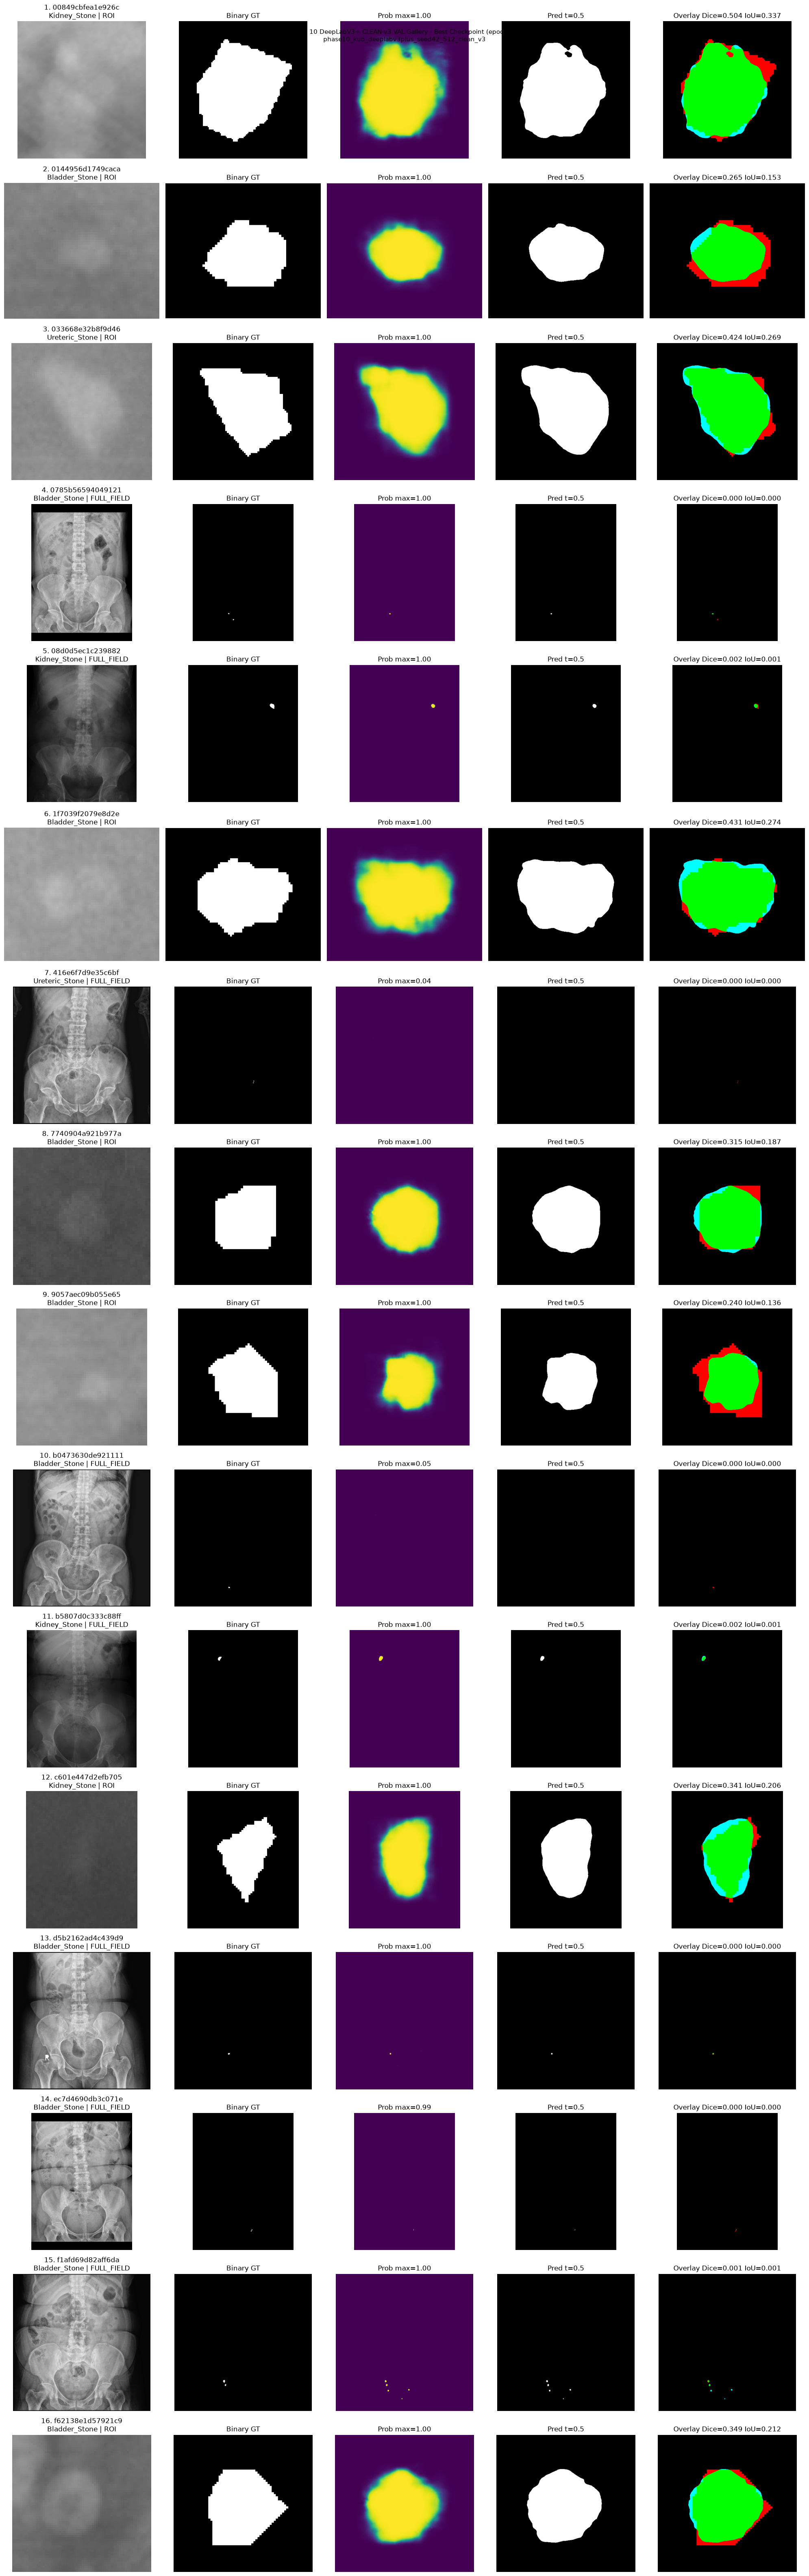

Metrics saved: D:\Softfors\jup\reports\tables\phase10_deeplabv3plus_clean_v3_val_gallery_metrics.csv

=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===
Subset mean Dice: 0.179641
Subset mean IoU : 0.111016

Authoritative full-KUB-VAL (280 cases):
  Dice=0.7509140344161673 IoU=0.6460492792430865
  Precision=0.7943328495850855 Recall=0.7822983241135557

Gallery means do NOT replace authoritative metrics.


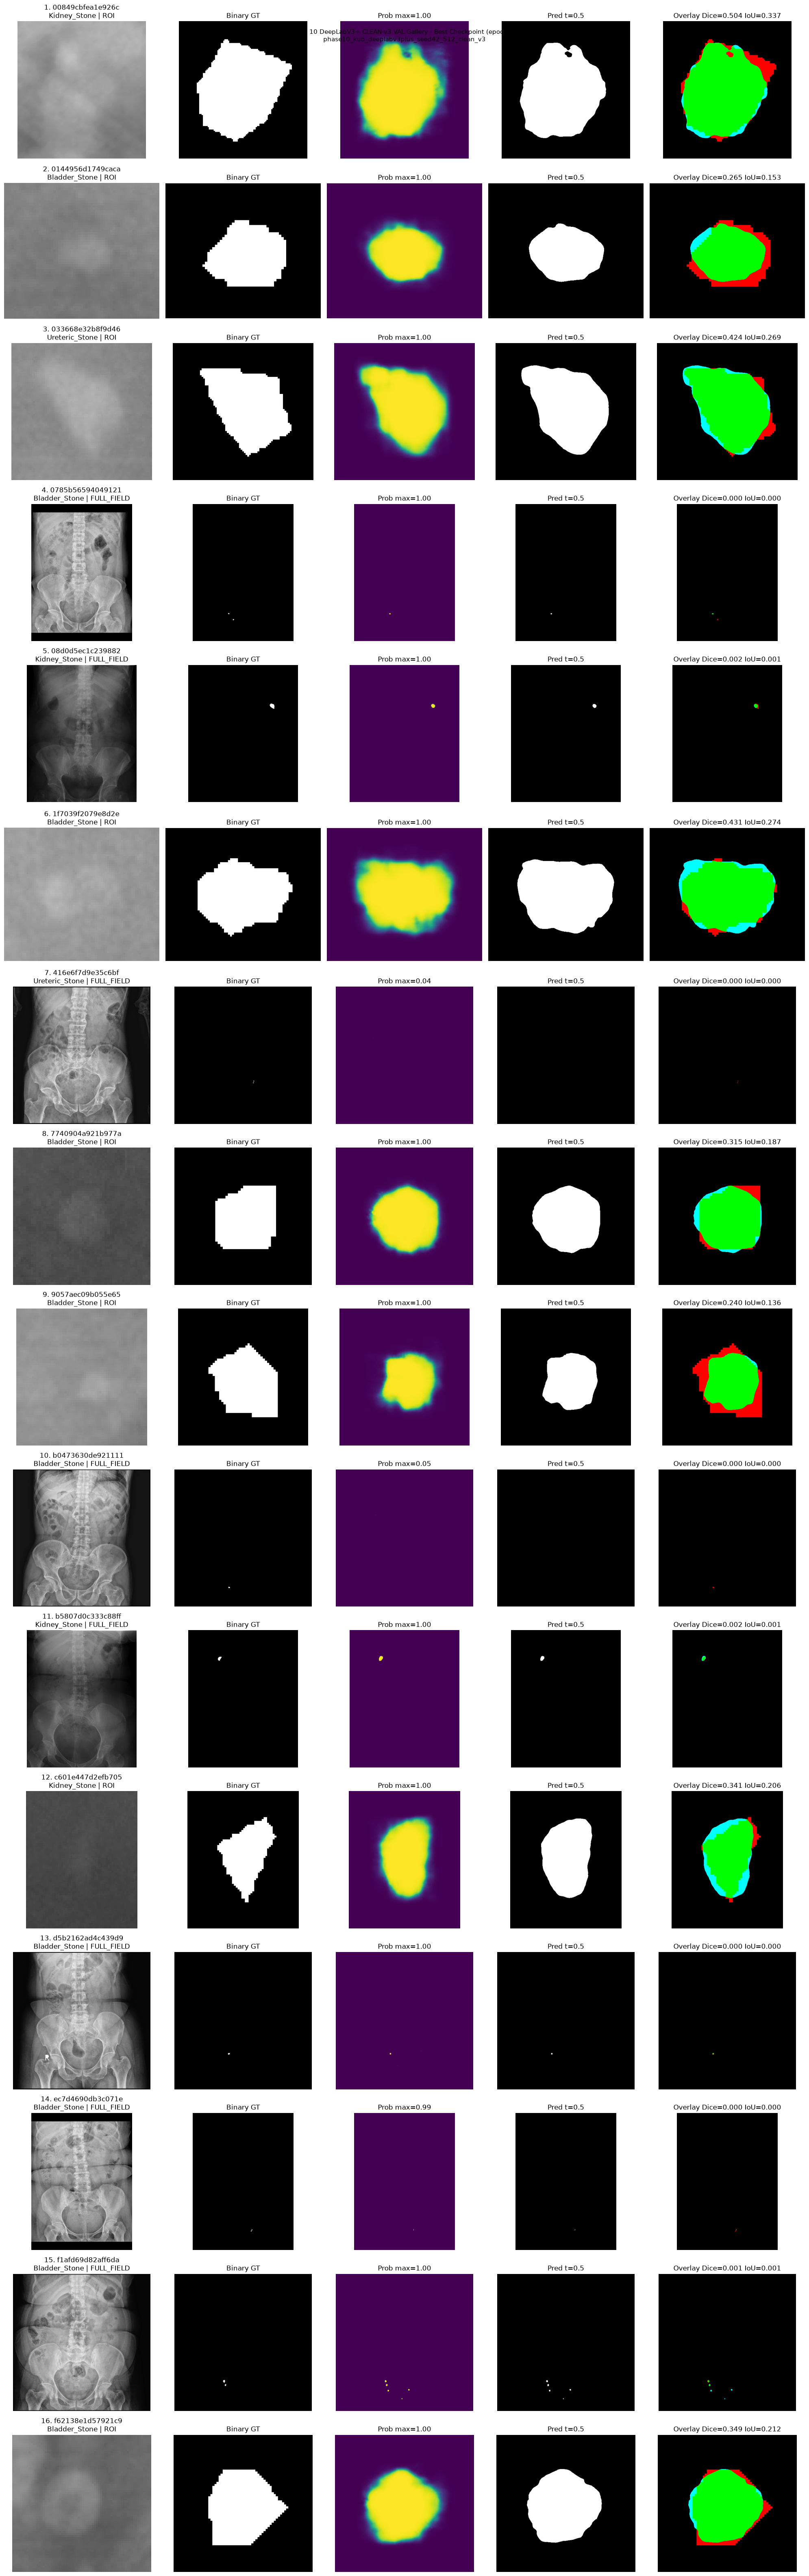

In [16]:
n = len(gal)
fig, axes = plt.subplots(n, 5, figsize=(20, 4*n))
fig.suptitle(f'Phase 10 DeepLabV3+ CLEAN-v3 VAL Gallery - Best Checkpoint (epoch {hi["best_epoch"]})\n{rv.EXPERIMENT_ID}', fontsize=11)
TH = 0.5
recs = []
for idx,(_,row) in enumerate(gal.iterrows()):
    sid = row['sample_id']; ip = Path(row['image_path']); mp = Path(row['mask_path'])
    if not ip.exists() or not mp.exists():
        for ax in axes[idx]: ax.axis('off'); ax.set_title('MISSING')
        continue
    gt = binarize_mask(np.array(Image.open(mp).convert('L'))).astype(np.uint8)
    prob,(nw,nh),(pl,pt) = rv.predict_on_val_sample(model, device, ip, target_size=512)
    gtr = np.array(Image.fromarray(gt).resize((nw,nh), Image.NEAREST))
    pred = (prob>=TH).astype(np.uint8)
    mm = binary_metrics(torch.from_numpy(gtr).float().unsqueeze(0),
                        torch.from_numpy(pred).float().unsqueeze(0), threshold=0.5)
    dice, iou = float(mm['dice']), float(mm['iou'])
    im = Image.open(ip).convert('L'); native = im.size; arr = np.array(im)
    ov = np.zeros((*pred.shape,3), dtype=np.uint8)
    ov[...,0]=gtr*255; ov[...,1]=pred*255
    both = gtr & pred
    ov[...,0]=np.where(both,0,ov[...,0]); ov[...,1]=np.where(both,255,ov[...,1])
    ov[...,2]=np.where((gtr==0)&(pred==1),255,0)
    A = axes[idx]
    A[0].imshow(arr,cmap='gray',vmin=0,vmax=255)
    A[0].set_title(f'{idx+1}. {sid[:16]}\n{row["category"]} | {row["acquisition_type"]}')
    A[1].imshow(gtr,cmap='gray',vmin=0,vmax=1); A[1].set_title('Binary GT')
    A[2].imshow(prob,cmap='viridis',vmin=0,vmax=1); A[2].set_title(f'Prob max={prob.max():.2f}')
    A[3].imshow(pred,cmap='gray',vmin=0,vmax=1); A[3].set_title(f'Pred t={TH}')
    A[4].imshow(ov); A[4].set_title(f'Overlay Dice={dice:.3f} IoU={iou:.3f}')
    for ax in A: ax.axis('off')
    recs.append({'gallery_index':idx+1,'sample_id':sid,'patient_id':row['patient_id'],
                 'category':row['category'],'acquisition_type':row['acquisition_type'],
                 'native_width':native[0],'native_height':native[1],
                 'pred_width':nw,'pred_height':nh,'dice':dice,'iou':iou})
plt.tight_layout()
gf = PROJECT_ROOT / 'reports' / 'figures' / 'phase10_deeplabv3plus_clean_v3_val_gallery.png'
fig.savefig(gf, dpi=150, bbox_inches='tight')
print(f'Gallery saved: {gf}')
display(fig)

mdf = pd.DataFrame(recs)
mpath = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_deeplabv3plus_clean_v3_val_gallery_metrics.csv'
mdf.to_csv(mpath, index=False)
print(f'Metrics saved: {mpath}')
print()
print('=== DETERMINISTIC_GALLERY_SUBSET_ONLY ===')
print(f'Subset mean Dice: {mdf["dice"].mean():.6f}')
print(f'Subset mean IoU : {mdf["iou"].mean():.6f}')
print()
print('Authoritative full-KUB-VAL (280 cases):')
br = df.loc[df['val_dice'].idxmax()]
print(f'  Dice={br["val_dice"]:.16f} IoU={br["val_iou"]:.16f}')
print(f'  Precision={br["val_precision"]:.16f} Recall={br["val_recall"]:.16f}')
print()
print('Gallery means do NOT replace authoritative metrics.')


## 17. Authoritative Aggregate VAL Metrics


In [17]:
br = df.loc[df['val_dice'].idxmax()]
summary = pd.DataFrame([{
 'experiment_id': rv.EXPERIMENT_ID, 'architecture':'deeplabv3plus',
 'backbone':'resnet50', 'backbone_pretrained': False, 'parameter_count': 40340769,
 'manifest_version':'phase4_v3','taxonomy_id':'kub_size_clean_v3_v1',
 'best_epoch':int(br['epoch']),'best_val_macro_dice':float(br['val_dice']),
 'val_macro_iou':float(br['val_iou']),'val_precision':float(br['val_precision']),
 'val_recall':float(br['val_recall']),'final_epoch':int(df['epoch'].iloc[-1]),
 'stop_reason':'EARLY_STOP','early_stop_bad_epochs':int(df['bad_epochs'].iloc[-1]),
 'config_sha': rv.EXPECTED_CONFIG_SHA,'history_sha': ca.get('history_sha'),
 'best_checkpoint_sha': ca.get('best_checkpoint_sha'),
 'latest_checkpoint_sha': ca.get('latest_checkpoint_sha'),
}])
sp = PROJECT_ROOT / 'reports' / 'tables' / 'phase10_deeplabv3plus_clean_v3_best_val_summary.csv'
summary.to_csv(sp, index=False)
print(f'Saved: {sp}')
print(summary.T.to_string())


Saved: D:\Softfors\jup\reports\tables\phase10_deeplabv3plus_clean_v3_best_val_summary.csv
                                                                                      0
experiment_id                             phase10_kub_deeplabv3plus_seed42_512_clean_v3
architecture                                                              deeplabv3plus
backbone                                                                       resnet50
backbone_pretrained                                                               False
parameter_count                                                                40340769
manifest_version                                                              phase4_v3
taxonomy_id                                                        kub_size_clean_v3_v1
best_epoch                                                                           52
best_val_macro_dice                                                            0.750914
val_macro_iou                 

## 18. Limitations

1. VAL-only; TEST locked (reads = 0).
2. Reviews DeepLabV3+ alone — **no cross-model comparison, no ranking, no winner**.
3. Single seed (42); no significance testing performed.
4. Gallery metrics are `DETERMINISTIC_GALLERY_SUBSET_ONLY` (16 cases), not 280-case VAL.
5. `base_channels: 32` appears in config for factory-signature compatibility but is
   **unused** by DeepLabV3+ (canonical decoder width is 256) — expected, not a defect.
6. DeepLabV3+ uses a randomly initialized ResNet-50 (no pretraining) by historical design;
   results are not comparable to a pretrained-backbone variant.


## 19. Historical-v2 Separation

| Property | HISTORICAL_v2 | CLEAN_v3 |
|----------|---------------|----------|
| Experiment | `phase10_kub_deeplabv3plus_seed42_512` | `…_clean_v3` |
| Manifest | `phase4_v2` (contaminated) | `phase4_v3` (remediated) |
| Taxonomy | none | `kub_size_clean_v3_v1` |
| Best epoch | 37 | see §17 |
| Final epoch | 52 | see §17 |
| Best VAL Dice | 0.7487905025482178 | see §17 |

Different TRAIN/VAL membership (v2 KUB 1979/283 vs v3 1978/280); do not attribute any
difference solely to leakage remediation.


## 20. Current Phase-10 Status

| Model | clean-v3 run | Status |
|---|---|---|
| UNet (Phase 09) | `phase9_…_clean_v3` | COMPLETE |
| Attention U-Net (1A) | `phase10_…_attention_unet_…_clean_v3` | COMPLETE |
| UNet++ (1B) | `phase10_…_unetpp_…_clean_v3` | COMPLETE |
| **DeepLabV3+ (1C)** | `phase10_…_deeplabv3plus_…_clean_v3` | **COMPLETE (this notebook)** |
| Final comparison | — | **NOT STARTED** |

**NO WINNER DECLARED.** All four runs are single-seed and descriptive; the final
comparison requires separate authorization.


## 21. Artifact Hashes


In [18]:
s = rv.full_integrity_summary()
print('Overall pass:', s['overall_pass'])
assert s['overall_pass']

def _sh(p): return rv.sha256_file(Path(p))
R = PROJECT_ROOT
reg = pd.DataFrame([
 {'artifact':'config','sha256':_sh(rv.CONFIG_PATH)},
 {'artifact':'history','sha256':_sh(rv.HISTORY_PATH)},
 {'artifact':'best_checkpoint','sha256':_sh(rv.BEST_PT)},
 {'artifact':'latest_checkpoint','sha256':_sh(rv.LATEST_PT)},
 {'artifact':'taxonomy','sha256':_sh(rv.TAXONOMY_ARTIFACT)},
 {'artifact':'training_runner','sha256':_sh(rv.TRAINING_RUNNER)},
 {'artifact':'protocol_diff','sha256':_sh(rv.PROTOCOL_DIFF)},
 {'artifact':'epoch_results_table','sha256':_sh(rv.EPOCH_TABLE_CSV)},
 {'artifact':'review_support_code','sha256':_sh(R/'notebooks'/'phasewise'/'phase_10_baseline_comparison'/'code'/'phase10_deeplabv3plus_review.py')},
 {'artifact':'canonical_gallery_selection','sha256':rv.CANONICAL_GALLERY_SHA},
 {'artifact':'gallery_metrics','sha256':_sh(R/'reports'/'tables'/'phase10_deeplabv3plus_clean_v3_val_gallery_metrics.csv')},
 {'artifact':'best_val_summary','sha256':_sh(R/'reports'/'tables'/'phase10_deeplabv3plus_clean_v3_best_val_summary.csv')},
])
rp = R / 'reports' / 'tables' / 'phase10_deeplabv3plus_clean_v3_artifact_registry.csv'
reg.to_csv(rp, index=False)
print(f'Registry saved: {rp}')
print(reg.to_string(index=False))


Overall pass: True


Registry saved: D:\Softfors\jup\reports\tables\phase10_deeplabv3plus_clean_v3_artifact_registry.csv
                   artifact                                                           sha256
                     config a5220e3135618513a71e0094197b2cffe0aef9334f7d53e39642c7a00ddd5b57
                    history 9c3a4611f0f38b474aa18537b0509bf9a4cb539baf077e6ba12c7880a73cd01f
            best_checkpoint f519027ba1a3a4d6212d83fecd4379f61f71bc05b0751924b9660da08d597dad
          latest_checkpoint 69267fd0cd2104cb474665bda68f3f9a1b4c2c4dc9e074b603fea921434022ed
                   taxonomy 89031c51a35c24f6f939fd6206fde6002a019d4bda24ce8cb21988f04db0f0d6
            training_runner d1c5174c3bc6db09f03756ee93f2cf1d122f7a52731d88577da5f8c6a5ef3f33
              protocol_diff 80b3cb6fe4809abb0baada882c4cc1c305b16c0f10b1c7a0c0f98b84e7ce1fef
        epoch_results_table 8320b24653129f2bbde10cd7084bb6ef7741fb7756cdc22c7a3c3873684252fe
        review_support_code 624b9182a76641475dbffa98b3f1b04f40e

## 22. Stop Boundary


In [19]:
print('=== REVIEWER BOUNDARY ===')
print('Optimizer steps        : 0')
print('Training epochs        : 0')
print('Checkpoint writes      : 0')
print('best/latest modified   : NO')
print('history/config modified: NO')
print('TEST image/mask reads  : 0')
print('TEST metrics / visuals : 0')
print('Final comparison       : NOT STARTED')
print('Winner declared        : NO')
print('Phase 11               : NOT STARTED')
print()
print('REVIEWER BOUNDARY - PASS')


=== REVIEWER BOUNDARY ===
Optimizer steps        : 0
Training epochs        : 0
Checkpoint writes      : 0
best/latest modified   : NO
history/config modified: NO
TEST image/mask reads  : 0
TEST metrics / visuals : 0
Final comparison       : NOT STARTED
Winner declared        : NO
Phase 11               : NOT STARTED

REVIEWER BOUNDARY - PASS
